**ESOPHAGEAL CANCER CLASSIFICATION USING INCEPTIONV3 FOR SAVE IMAGES**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt

train_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/train'
#val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/SAVE_split/val'
test_dir = '/content/drive/MyDrive/Arvind/Arvind/combined_split/test'

# Parameters
IMAGE_SIZE = (640, 640)  # InceptionV3 requires images of size 299x299
BATCH_SIZE = 32
EPOCHS = 300

# Load datasets
train_dataset = image_dataset_from_directory(
    train_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

#val_dataset = image_dataset_from_directory(
    #val_dir,
    #shuffle=True,
    #batch_size=BATCH_SIZE,
    #image_size=IMAGE_SIZE
#)

test_dataset = image_dataset_from_directory(
    test_dir,
    shuffle=False,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)



Found 2880 files belonging to 14 classes.
Found 320 files belonging to 14 classes.


In [5]:
# Define data augmentation
#data_augmentation = tf.keras.Sequential([
    #tf.keras.layers.RandomFlip("horizontal"),
    #tf.keras.layers.RandomRotation(0.2),
    #tf.keras.layers.RandomZoom(0.2),
#])

# Preprocess input for InceptionV3
preprocess_input = tf.keras.applications.inception_v3.preprocess_input

# Load InceptionV3 model without the top layer
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(640, 640, 3))

# Freeze the base model layers
base_model.trainable = False

# Build model
x = inputs = tf.keras.Input(shape=(640, 640, 3))
#x = data_augmentation(inputs)  # Apply data augmentation
x = preprocess_input(x)        # Preprocess input
x = base_model(x, training=False)  # Pass through base model
x = GlobalAveragePooling2D()(x)  # Global Average Pooling
x = Dropout(0.5)(x)              # Regularization with Dropout

# Determine the number of classes
num_classes = len(train_dataset.class_names) # Get number of classes from class_names
outputs = Dense(num_classes, activation='softmax')(x)  # Output layer

model = Model(inputs, outputs)

# Compile model
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [6]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)           │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ true_divide (TrueDivide)             │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ subtract (Subtract)                  │ (None, 640, 640, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ inception_v3 (Functional)            │ (None, 18, 18, 2048)        │      21,802,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 14)                  │          28,686 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 21,831,470 (83.28 MB)

 Trainable params: 28,686 (112.05 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [21]:
# Train the model without callbacks
history = model.fit(
    train_dataset,
    #validation_data=val_dataset,
    epochs=300
)



Epoch 1/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.4641 - loss: 1.6397
Epoch 2/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.5730 - loss: 1.3548
Epoch 3/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.5768 - loss: 1.2590
Epoch 4/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6084 - loss: 1.1584
Epoch 5/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6484 - loss: 1.0530
Epoch 6/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.6477 - loss: 1.0144
Epoch 7/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6620 - loss: 1.0052
Epoch 8/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6718 - loss: 0.9644
Epoch 9/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6830 - loss: 0.9197
Epoch 10/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.6811 - loss: 0.9110
Epoch 11/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.7108 - loss: 0.8553
Epoch 12/300
90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step

In [22]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f'Test Accuracy: {test_accuracy * 100:.2f}%')



10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.6471 - loss: 0.9427
Test Accuracy: 70.31%


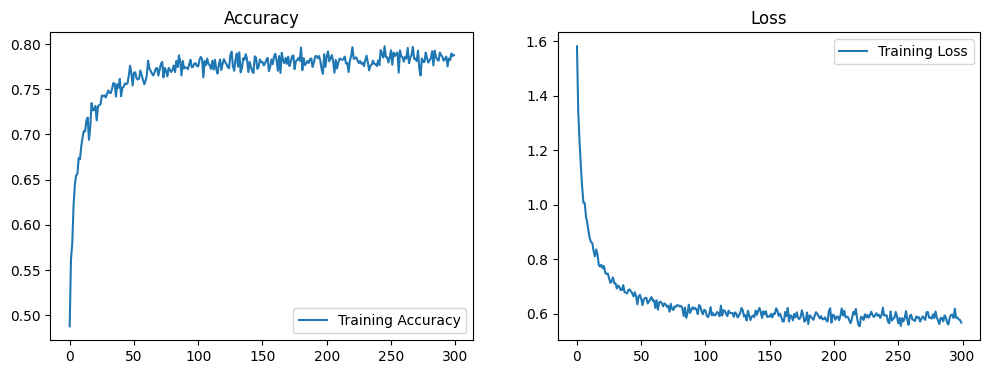

In [23]:
# Plot training history
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
#plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
#plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()



In [24]:
# Generate Classification Report
from sklearn.metrics import classification_report
import numpy as np

y_true = np.concatenate([y for x, y in test_dataset], axis=0)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=test_dataset.class_names))


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step
Classification Report:
              precision    recall  f1-score   support

        n1.n       0.69      0.55      0.61        20
      n2.dys       0.58      0.55      0.56        20
       n3.ca       0.58      0.88      0.70        25
       n4.ev       0.59      0.40      0.48        25
       n5.ec       0.62      0.75      0.68        20
      n6.ero       0.62      0.50      0.56        10
        w1.n       0.59      0.65      0.62        20
      w2.dys       0.64      0.70      0.67        20
       w3.ca       0.82      0.82      0.82        40
       w4.ev       0.81      0.72      0.76        40
       w5.ec       0.65      0.55      0.59        20
      w6.ero       0.62      0.65      0.63        20
        w7.d       1.00      0.95      0.97        20
        w8.s       0.90      0.95      0.93        20

    accuracy                           0.70       320
   macro avg       0.69      0.69      0.69       320
weighted avg     

In [25]:
import tensorflow as tf

model.save_weights('/content/drive/MyDrive/Arvind/inception_V3_weights.weights.h5')  # Add '.weights' before '.h5'


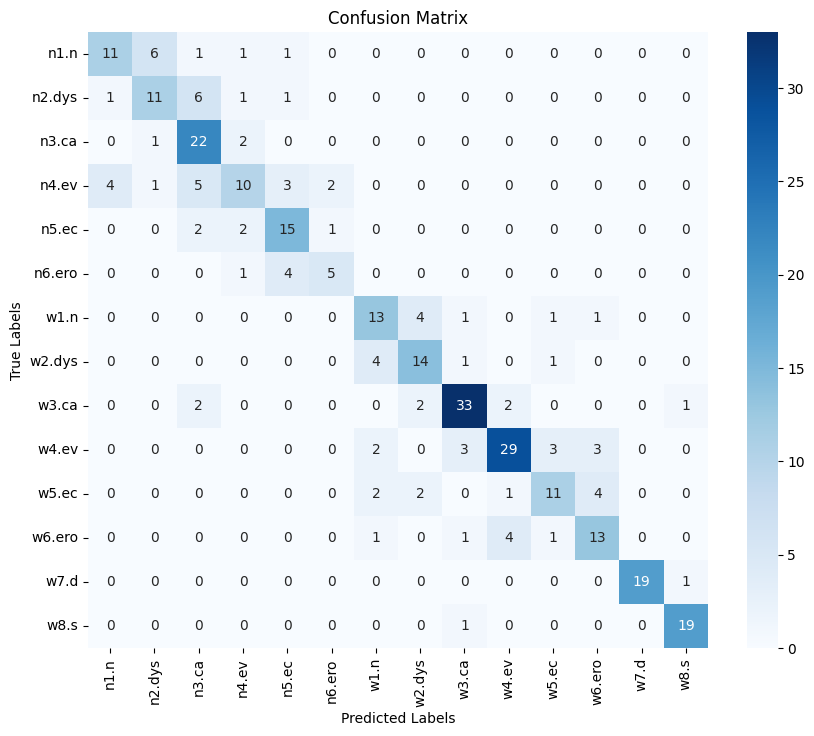

In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=test_dataset.class_names, yticklabels=test_dataset.class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


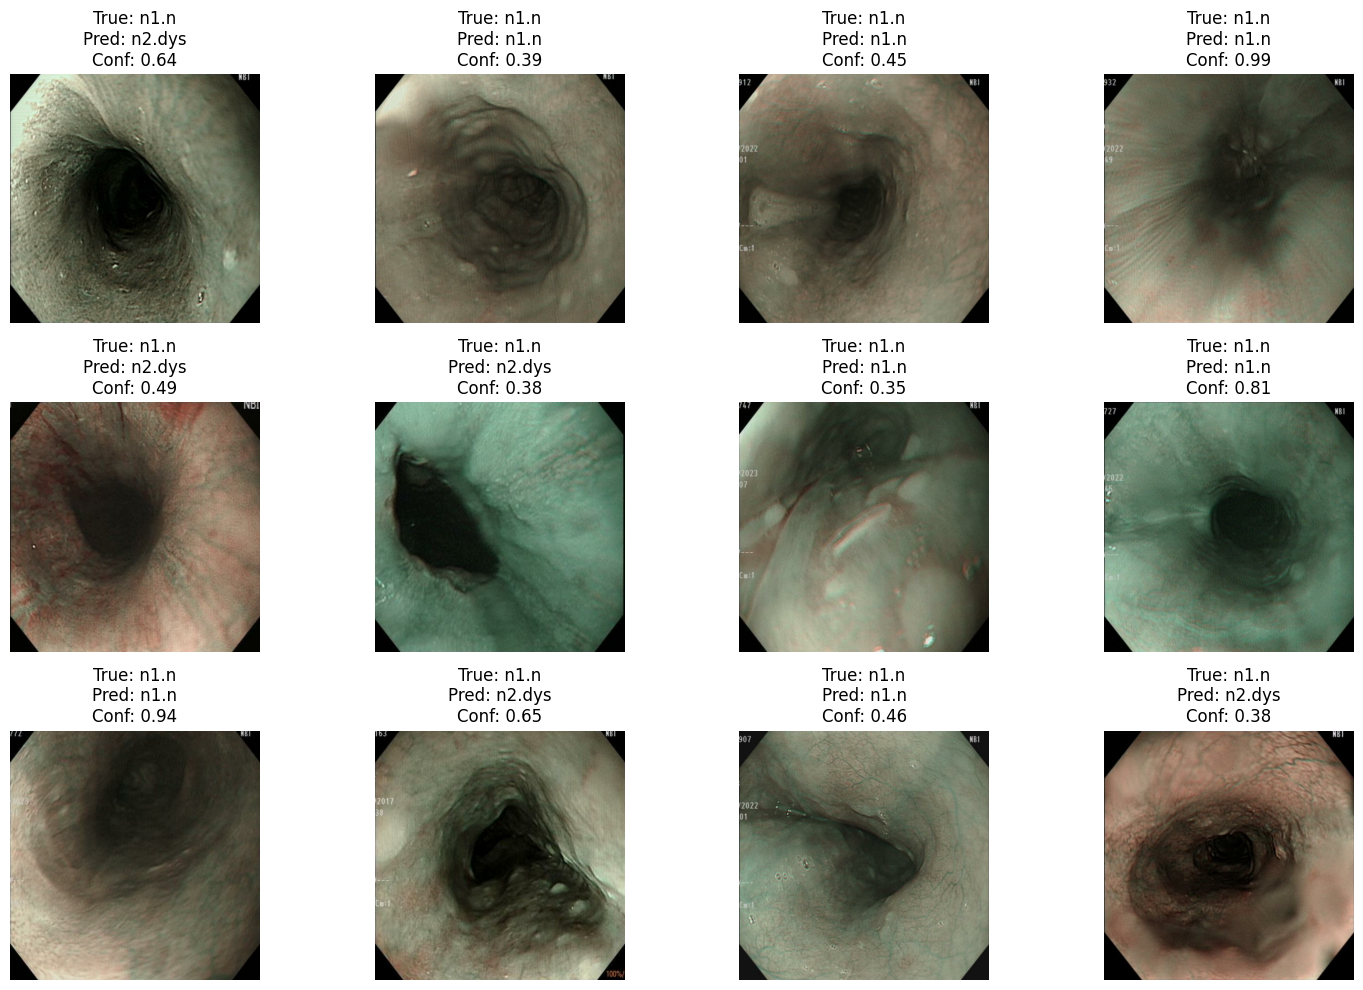

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Load the saved model weights
model.load_weights('/content/drive/MyDrive/Arvind/inception_V3_weights.weights.h5')

# Get a batch of images and labels from the test dataset
images, labels = next(iter(test_dataset))

# Select 12 images
num_images_to_display = 12
images_to_display = images[:num_images_to_display]
labels_to_display = labels[:num_images_to_display]

# Predict the labels for the selected images
predictions = model.predict(images_to_display)
predicted_labels = np.argmax(predictions, axis=1)
confidence = np.max(predictions, axis=1)

# Display the images with their true and predicted labels
plt.figure(figsize=(15, 10))
for i in range(num_images_to_display):
  plt.subplot(3, 4, i + 1)
  plt.imshow(images_to_display[i].numpy().astype("uint8"))
  plt.title(f"True: {test_dataset.class_names[labels_to_display[i]]}\nPred: {test_dataset.class_names[predicted_labels[i]]}\nConf: {confidence[i]:.2f}")
  plt.axis("off")

plt.tight_layout()
plt.show()
